# Лабораторная работа №2. Обучение нейронной сети с нуля

**Вариант 5:** Fashion-MNIST, сеть 784 → 256 → 10, Sigmoid, начальный learning rate 0.05.

В этой работе я сравниваю ручное обновление весов с SGD из PyTorch, выбираю скорость обучения и проверяю, помогают ли dropout, weight decay и ранняя остановка.

Весь код и отчёт находятся здесь. Ячейки нужно запускать сверху вниз. При первом запуске Fashion-MNIST скачается в папку data. Полный расчёт занимает несколько минут на CPU.

## 1. Подготовка

Фиксирую seed, чтобы повторные запуски были сопоставимы. Обучение выполняю на CPU с одним потоком. Окружение проекта — **Python 3.12.12**.

Версии библиотек: torch==2.14.0+cpu, torchvision==0.29.0+cpu, numpy==2.5.3, matplotlib==3.11.2. Они закреплены в requirements.txt; команды создания окружения и запуска приведены в README.

In [1]:
import copy
import random
import platform
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torchvision
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, random_split
from torchvision import datasets, transforms
from IPython.display import display, Markdown

VARIANT = 5
SEED = 42
START_LR = 0.05
LR_GRID = [0.001, 0.01, 0.05, 0.1, 0.5, 10.0]
COMPARE_EPOCHS = 8
LR_EPOCHS = 8
REG_EPOCHS = 25
CLASSES = ['Футболка', 'Брюки', 'Свитер', 'Платье', 'Пальто',
           'Сандалии', 'Рубашка', 'Кроссовки', 'Сумка', 'Ботинки']

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True)

torch.set_num_threads(1)
set_seed()
plt.style.use('default')
print(f'Python {platform.python_version()}, PyTorch {torch.__version__}')
print(f'torchvision {torchvision.__version__}, NumPy {np.__version__}')
print(f'Matplotlib {plt.matplotlib.__version__}, вариант {VARIANT}, seed {SEED}')

Python 3.12.12, PyTorch 2.14.0+cpu
torchvision 0.29.0+cpu, NumPy 2.5.3
Matplotlib 3.11.2, вариант 5, seed 42


## 2. Данные

В Fashion-MNIST 60 000 обучающих изображений одежды размером 28 × 28. Разделяю их на 48 000 объектов для обучения и 12 000 для валидации с помощью random_split.

Пиксели перевожу из диапазона 0–255 в 0–1. Среднее и стандартное отклонение здесь не вычисляются, поэтому в нормализации нет подгонки по валидационной выборке.

После разделения сохраняю изображения в TensorDataset. Это даёт тот же результат, что ToTensor, и ускоряет повторные эксперименты: изображения не приходится заново преобразовывать из PIL в каждой эпохе.

In [2]:
def load_data(root=Path('data')):
    """ToTensor: фиксированное деление на 255, без fit по всей выборке."""
    full = datasets.FashionMNIST(root=str(root), train=True, download=True,
                                transform=transforms.ToTensor())
    train, val = random_split(full, [48000, 12000],
                             generator=torch.Generator().manual_seed(SEED))
    assert not set(train.indices).intersection(val.indices)
    # Кэшируем эквивалент ToTensor после разделения: избавляемся от PIL на каждом шаге.
    def cache(split):
        idx = torch.tensor(split.indices)
        x = full.data[idx].unsqueeze(1).to(torch.float32).div_(255)
        return TensorDataset(x, full.targets[idx].clone())
    train_ds, val_ds = cache(train), cache(val)
    meta = {'train_size': len(train_ds), 'val_size': len(val_ds),
            'train_indices': train.indices, 'val_indices': val.indices,
            'normalization': 'uint8 / 255; no fitted statistics',
            'train_class_counts': torch.bincount(train_ds.tensors[1], minlength=10).tolist(),
            'val_class_counts': torch.bincount(val_ds.tensors[1], minlength=10).tolist()}
    return train_ds, val_ds, meta

train_ds, val_ds, data_info = load_data()
print(f'Обучение: {len(train_ds)} изображений')
print(f'Валидация: {len(val_ds)} изображений')
print('Число объектов каждого класса на валидации:')
print(dict(zip(CLASSES, data_info['val_class_counts'])))

Обучение: 48000 изображений
Валидация: 12000 изображений
Число объектов каждого класса на валидации:
{'Футболка': 1268, 'Брюки': 1248, 'Свитер': 1175, 'Платье': 1148, 'Пальто': 1193, 'Сандалии': 1203, 'Рубашка': 1212, 'Кроссовки': 1134, 'Сумка': 1195, 'Ботинки': 1224}


## 3. Модель

Изображение разворачивается в вектор из 784 чисел. Затем идут линейный слой на 256 нейронов, Sigmoid и выходной слой на 10 классов.

В базовой модели dropout отсутствует. Он добавляется только при dropout > 0 в отдельном эксперименте с регуляризацией.


In [3]:
class MLP(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        layers = [nn.Linear(784, 256), nn.Sigmoid()]
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        layers.append(nn.Linear(256, 10))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        x = x.view(x.size(0), -1)
        return self.net(x)

print(MLP())

MLP(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): Sigmoid()
    (2): Linear(in_features=256, out_features=10, bias=True)
  )
)


## 4. Обучение и проверка качества

В ручном цикле PyTorch вычисляет градиенты через loss.backward(), а веса обновляются обычным вычитанием под no_grad(). Перед каждым батчем старые градиенты очищаются.

Для сравнения пишу второй цикл, где обновление выполняет optimizer.step(). Weight decay добавляет к градиенту слагаемое weight_decay × p.

При валидации включаю eval() и отключаю расчёт градиентов. Считаю среднюю ошибку, accuracy и macro-F1. Macro-F1 — среднее F1 по всем десяти классам, поэтому каждый класс имеет одинаковый вес.

In [4]:
def train_epoch_manual(model, loader, criterion, lr, weight_decay=0.0):
    """Autograd вычисляет градиенты, обновление параметров полностью ручное."""
    model.train()
    loss_sum = 0.0
    for x, y in loader:
        model.zero_grad(set_to_none=True)
        logits = model(x)
        loss = criterion(logits, y)
        if not torch.isfinite(loss):
            raise FloatingPointError('Нефинитный train loss')
        loss.backward()
        with torch.no_grad():
            for p in model.parameters():
                if p.grad is not None:
                    p -= lr * (p.grad + weight_decay * p)
        loss_sum += loss.item() * len(y)
    return loss_sum / len(loader.dataset)


def train_epoch_optim(model, loader, criterion, optimizer):
    model.train()
    loss_sum = 0.0
    for x, y in loader:
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = criterion(logits, y)
        if not torch.isfinite(loss):
            raise FloatingPointError('Нефинитный train loss')
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * len(y)
    return loss_sum / len(loader.dataset)

In [5]:
@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    cm = torch.zeros((10, 10), dtype=torch.int64)
    loss_sum = 0.0
    for x, y in loader:
        logits = model(x)
        loss_sum += criterion(logits, y).item() * len(y)
        pred = logits.argmax(1)
        cm += torch.bincount(10 * y + pred, minlength=100).reshape(10, 10)
    tp = cm.diag().double()
    denominator = cm.sum(0) + cm.sum(1)
    f1 = torch.where(denominator > 0, 2 * tp / denominator.clamp_min(1), 0.)
    return {'loss': loss_sum / len(loader.dataset),
            'accuracy': (tp.sum() / cm.sum()).item(),
            'macro_f1': f1.mean().item(), 'confusion_matrix': cm.tolist()}

Одна функция запускает каждый эксперимент с одинаковыми начальными весами и порядком батчей. Для перемешивания данных использую отдельный генератор, чтобы dropout не влиял на порядок изображений.

Ранняя остановка следит за ошибкой валидации. Если она не улучшается три эпохи подряд, обучение прекращается и восстанавливаются лучшие веса. Без ранней остановки сохраняется модель последней эпохи.

In [6]:
def run_experiment(train_ds, val_ds, name, lr, epochs, method='manual',
                   dropout=0.0, weight_decay=0.0, patience=None):
    set_seed()
    model = MLP(dropout)
    # Отдельные генераторы: инициализация, dropout и валидация не меняют перестановки.
    train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=0,
                              generator=torch.Generator().manual_seed(SEED))
    val_loader = DataLoader(val_ds, batch_size=256, shuffle=False, num_workers=0,
                            generator=torch.Generator().manual_seed(SEED + 1))
    criterion = nn.CrossEntropyLoss()
    optimizer = None
    if method != 'manual':
        optimizer = torch.optim.SGD(model.parameters(), lr=lr, weight_decay=weight_decay,
                                    momentum=0.9 if method == 'momentum' else 0.0)
    history, best_state, best_loss, best_epoch, wait = [], None, float('inf'), 0, 0
    for epoch in range(1, epochs + 1):
        train_loss = (train_epoch_manual(model, train_loader, criterion, lr, weight_decay)
                      if method == 'manual' else
                      train_epoch_optim(model, train_loader, criterion, optimizer))
        val = evaluate(model, val_loader, criterion)
        history.append({'epoch': epoch, 'train_loss': train_loss,
                        'val_loss': val['loss'], 'val_accuracy': val['accuracy'],
                        'val_macro_f1': val['macro_f1']})
        if val['loss'] < best_loss:
            best_loss, best_epoch, wait = val['loss'], epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
        if epoch == 1 or epoch % 4 == 0 or epoch == epochs:
            print(f'{name:22s} {epoch:02d}/{epochs} train={train_loss:.4f} '
              f'val={val["loss"]:.4f} acc={val["accuracy"]:.4f}', flush=True)
        if patience is not None and wait >= patience:
            break
    last = evaluate(model, val_loader, criterion)
    if patience is not None:
        model.load_state_dict(best_state)
    final = evaluate(model, val_loader, criterion)
    result = dict(name=name, lr=lr, method=method, dropout=dropout,
                  weight_decay=weight_decay, patience=patience, budget=epochs,
                  epochs_run=len(history), best_epoch=best_epoch, best_val_loss=best_loss,
                  history=history, final=final, last=last)
    return result, model

In [7]:
def show_table(runs):
    lines = [
        '| Запуск | min val loss | Итоговый val loss | Accuracy | Macro-F1 | Эпох / лучшая |',
        '|---|---:|---:|---:|---:|---:|',
    ]
    for name, result in runs.items():
        metrics = result['final']
        lines.append(
            f"| {name} | {result['best_val_loss']:.5f} | {metrics['loss']:.5f} | "
            f"{metrics['accuracy']:.2%} | {metrics['macro_f1']:.5f} | "
            f"{result['epochs_run']} / {result['best_epoch']} |"
        )
    display(Markdown('\n'.join(lines)))


def plot_runs(runs, title):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout='constrained')
    keys = ['train_loss', 'val_loss', 'val_accuracy']
    titles = ['Ошибка на обучении', 'Ошибка на валидации', 'Accuracy на валидации']
    for i, (name, result) in enumerate(runs.items()):
        history = result['history']
        epochs = [row['epoch'] for row in history]
        for ax, key in zip(axes, keys):
            ax.plot(epochs, [row[key] for row in history],
                    label=name, linestyle=['-', '--', '-.', ':'][i % 4])
            if result['patience'] is not None:
                best = history[result['best_epoch'] - 1]
                ax.scatter(best['epoch'], best[key], s=25, zorder=5)
    for ax, title_part in zip(axes, titles):
        ax.set_title(title_part)
        ax.set_xlabel('Эпоха')
        ax.set_ylabel('Accuracy' if ax is axes[2] else 'Cross entropy')
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    fig.suptitle(title)
    display(fig)
    plt.close(fig)

## 5. Ручной SGD и torch.optim.SGD

Оба варианта обучаю восемь эпох с lr=0.05, без momentum и weight decay. При одинаковых весах и батчах они должны дать почти одинаковый результат: правило обновления одно и то же.

Ручной SGD             01/8 train=1.2258 val=0.7863 acc=0.7308
Ручной SGD             04/8 train=0.5401 val=0.5345 acc=0.8158
Ручной SGD             08/8 train=0.4588 val=0.4721 acc=0.8386
SGD PyTorch            01/8 train=1.2258 val=0.7863 acc=0.7308
SGD PyTorch            04/8 train=0.5401 val=0.5345 acc=0.8158
SGD PyTorch            08/8 train=0.4588 val=0.4721 acc=0.8386


| Запуск | min val loss | Итоговый val loss | Accuracy | Macro-F1 | Эпох / лучшая |
|---|---:|---:|---:|---:|---:|
| Ручной SGD | 0.47212 | 0.47212 | 83.86% | 0.83541 | 8 / 8 |
| SGD PyTorch | 0.47212 | 0.47212 | 83.86% | 0.83541 | 8 / 8 |

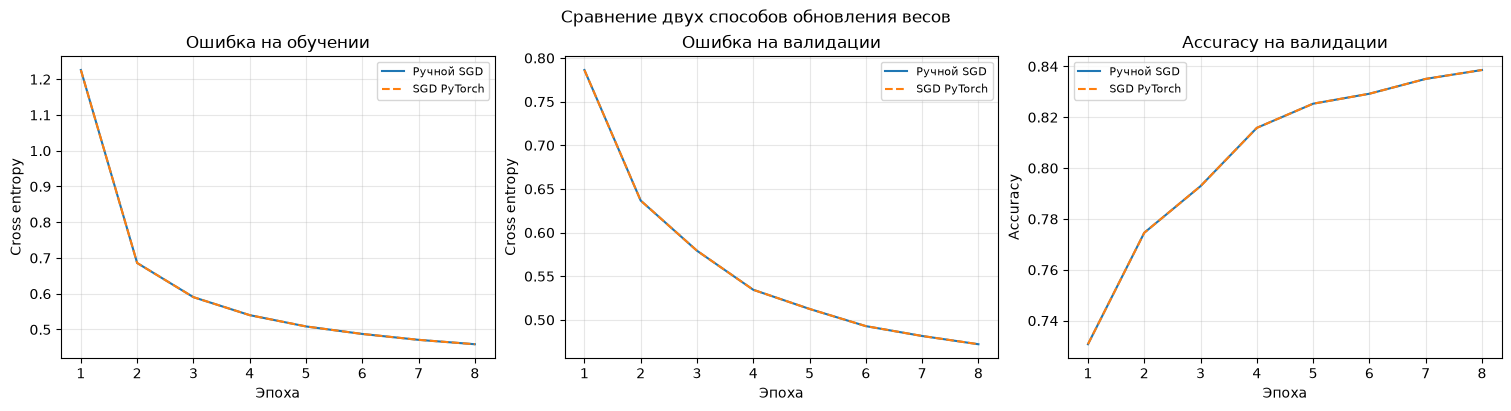

Максимальное различие весов: 6.855e-07


In [8]:
manual_result, manual_model = run_experiment(
    train_ds, val_ds, 'Ручной SGD', lr=START_LR, epochs=COMPARE_EPOCHS,
)
sgd_result, sgd_model = run_experiment(
    train_ds, val_ds, 'SGD PyTorch', lr=START_LR,
    epochs=COMPARE_EPOCHS, method='sgd',
)
comparison = {'Ручной SGD': manual_result, 'SGD PyTorch': sgd_result}
show_table(comparison)
plot_runs(comparison, 'Сравнение двух способов обновления весов')

max_difference = max(
    (a - b).abs().max().item()
    for a, b in zip(manual_model.parameters(), sgd_model.parameters())
)
print(f'Максимальное различие весов: {max_difference:.3e}')

Небольшое различие весов возможно из-за округления float32: ручное умножение и вычитание выполняются немного иначе, чем обновление в стандартном SGD. Для проверки правильности важны близкие веса, метрики и кривые.

## 6. Подбор learning rate

Проверяю шесть значений, включая исходное 0.05. Начальные веса и число эпох во всех запусках одинаковы. Лучший lr выбираю по минимальной ошибке на валидации.

Значение 0.001 помогает увидеть слишком медленное обучение, а 10.0 — поведение при слишком большом шаге.

lr=0.001               01/8 train=2.2779 val=2.2512 acc=0.3617
lr=0.001               04/8 train=2.1064 val=2.0737 acc=0.6138
lr=0.001               08/8 train=1.8008 val=1.7629 acc=0.6032
lr=0.01                01/8 train=1.9854 val=1.6180 acc=0.5288
lr=0.01                04/8 train=0.8935 val=0.8518 acc=0.7167
lr=0.01                08/8 train=0.6738 val=0.6748 acc=0.7578
lr=0.05                01/8 train=1.2258 val=0.7863 acc=0.7308
lr=0.05                04/8 train=0.5401 val=0.5345 acc=0.8158
lr=0.05                08/8 train=0.4588 val=0.4721 acc=0.8386
lr=0.1                 01/8 train=0.9675 val=0.6508 acc=0.7618
lr=0.1                 04/8 train=0.4746 val=0.4747 acc=0.8348
lr=0.1                 08/8 train=0.4150 val=0.4335 acc=0.8490
lr=0.5                 01/8 train=0.6846 val=0.4995 acc=0.8263
lr=0.5                 04/8 train=0.3888 val=0.3889 acc=0.8604
lr=0.5                 08/8 train=0.3305 val=0.3695 acc=0.8680
lr=10.0                01/8 train=1.6562 val=1.1913 acc

| Запуск | min val loss | Итоговый val loss | Accuracy | Macro-F1 | Эпох / лучшая |
|---|---:|---:|---:|---:|---:|
| lr=0.001 | 1.76287 | 1.76287 | 60.32% | 0.56529 | 8 / 8 |
| lr=0.01 | 0.67484 | 0.67484 | 75.78% | 0.75027 | 8 / 8 |
| lr=0.05 | 0.47212 | 0.47212 | 83.86% | 0.83541 | 8 / 8 |
| lr=0.1 | 0.43354 | 0.43354 | 84.90% | 0.84519 | 8 / 8 |
| lr=0.5 | 0.35741 | 0.36950 | 86.80% | 0.86409 | 8 / 7 |
| lr=10.0 | 0.61445 | 0.70643 | 79.24% | 0.78153 | 8 / 7 |

Выбран learning rate: 0.5


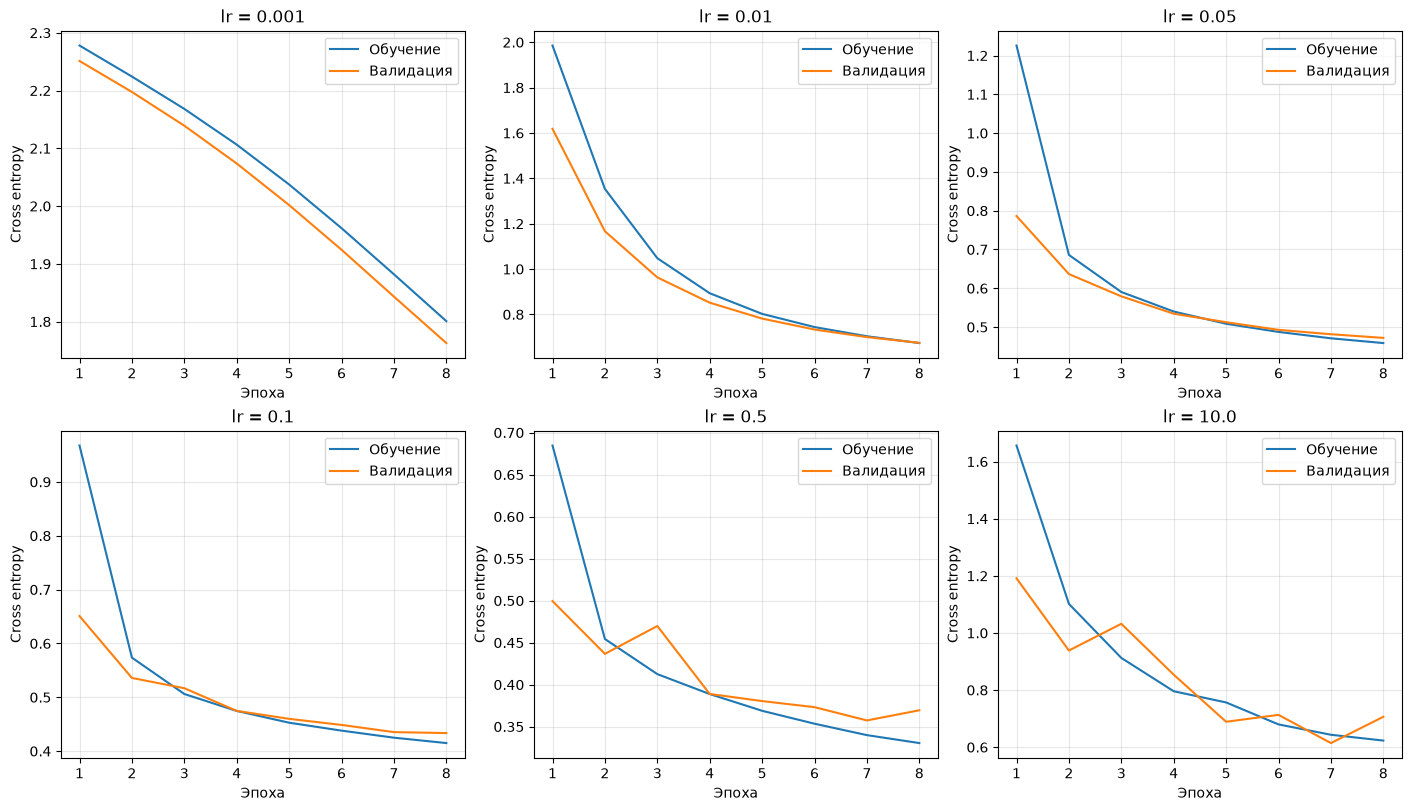

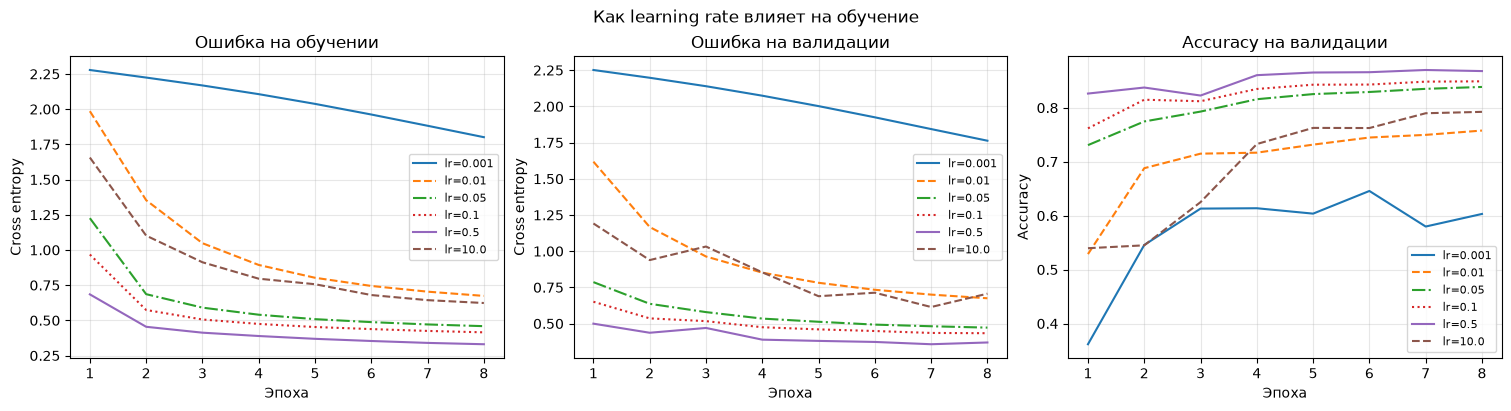

In [9]:
lr_results = {}
for lr in LR_GRID:
    result, _ = run_experiment(
        train_ds, val_ds, f'lr={lr}', lr=lr, epochs=LR_EPOCHS,
    )
    lr_results[lr] = result

best_lr = min(lr_results, key=lambda lr: lr_results[lr]['best_val_loss'])
show_table({f'lr={lr}': result for lr, result in lr_results.items()})
print(f'Выбран learning rate: {best_lr}')

fig, axes = plt.subplots(2, 3, figsize=(14, 8), layout='constrained')
for ax, (lr, result) in zip(axes.flat, lr_results.items()):
    history = result['history']
    epochs = [row['epoch'] for row in history]
    ax.plot(epochs, [row['train_loss'] for row in history], label='Обучение')
    ax.plot(epochs, [row['val_loss'] for row in history], label='Валидация')
    ax.set(title=f'lr = {lr}', xlabel='Эпоха', ylabel='Cross entropy')
    ax.legend()
    ax.grid(alpha=0.3)
display(fig)
plt.close(fig)
plot_runs({f'lr={lr}': result for lr, result in lr_results.items()},
          'Как learning rate влияет на обучение')

In [10]:
small = lr_results[0.001]
large = lr_results[10.0]
display(Markdown(
    f"При **lr=0.001** ошибка валидации за {LR_EPOCHS} эпох снизилась "
    f"с {small['history'][0]['val_loss']:.4f} до {small['final']['loss']:.4f}. "
    f"Модель обучается медленно. При **lr=10** итоговая ошибка равна "
    f"{large['final']['loss']:.4f}; на кривой видны колебания. "
    f"В этой сетке лучший результат дал **lr={best_lr}**: "
    f"минимальная ошибка валидации {lr_results[best_lr]['best_val_loss']:.4f}."
))

При **lr=0.001** ошибка валидации за 8 эпох снизилась с 2.2512 до 1.7629. Модель обучается медленно. При **lr=10** итоговая ошибка равна 0.7064; на кривой видны колебания. В этой сетке лучший результат дал **lr=0.5**: минимальная ошибка валидации 0.3574.

## 7. Регуляризация

С выбранным lr сравниваю три конфигурации: базовую сеть, dropout с вероятностью 0.2 и weight decay 0.0001. Максимум — 25 эпох, patience — 3.

Оцениваю регуляризацию по валидации. Более высокая ошибка на обучении сама по себе не означает, что регуляризация работает плохо.

Без регуляризации      01/25 train=0.6846 val=0.4995 acc=0.8263
Без регуляризации      04/25 train=0.3888 val=0.3889 acc=0.8604
Без регуляризации      08/25 train=0.3305 val=0.3695 acc=0.8680
Без регуляризации      12/25 train=0.2968 val=0.3460 acc=0.8767
Без регуляризации      16/25 train=0.2716 val=0.3393 acc=0.8768
Без регуляризации      20/25 train=0.2509 val=0.3115 acc=0.8893
Dropout 0.2            01/25 train=0.7095 val=0.4942 acc=0.8255
Dropout 0.2            04/25 train=0.4171 val=0.4009 acc=0.8550
Dropout 0.2            08/25 train=0.3621 val=0.3736 acc=0.8678
Dropout 0.2            12/25 train=0.3301 val=0.3513 acc=0.8750
Dropout 0.2            16/25 train=0.3100 val=0.3425 acc=0.8761
Dropout 0.2            20/25 train=0.2894 val=0.3213 acc=0.8871
Weight decay           01/25 train=0.6866 val=0.5024 acc=0.8258
Weight decay           04/25 train=0.3958 val=0.3933 acc=0.8596
Weight decay           08/25 train=0.3435 val=0.3779 acc=0.8658
Weight decay           12/25 train=0.316

| Запуск | min val loss | Итоговый val loss | Accuracy | Macro-F1 | Эпох / лучшая |
|---|---:|---:|---:|---:|---:|
| Без регуляризации | 0.31147 | 0.31147 | 88.93% | 0.88953 | 23 / 20 |
| Dropout 0.2 | 0.32091 | 0.32091 | 88.70% | 0.88535 | 22 / 19 |
| Weight decay | 0.32154 | 0.32154 | 88.59% | 0.88611 | 23 / 20 |

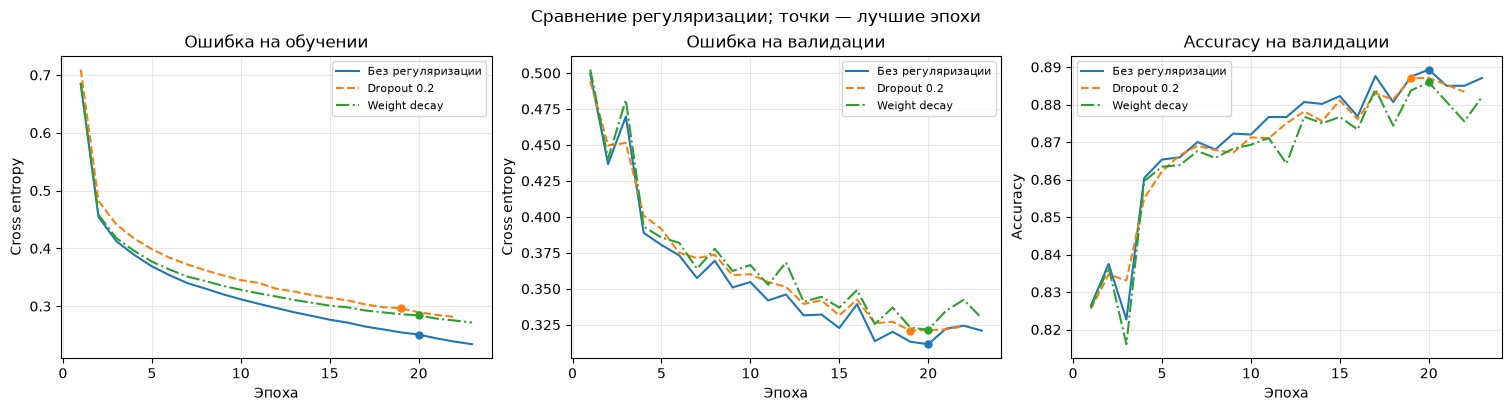

Лучшая конфигурация: Без регуляризации
Dropout 0.2: изменение val loss относительно базовой сети +0.00944
Weight decay: изменение val loss относительно базовой сети +0.01008


In [11]:
configs = {
    'Без регуляризации': {},
    'Dropout 0.2': {'dropout': 0.2},
    'Weight decay': {'weight_decay': 1e-4},
}
regularization = {}
trained_models = {}
for name, config in configs.items():
    result, model = run_experiment(
        train_ds, val_ds, name, lr=best_lr,
        epochs=REG_EPOCHS, patience=3, **config,
    )
    regularization[name] = result
    trained_models[name] = model

best_name = min(regularization, key=lambda name: regularization[name]['best_val_loss'])
best_result = regularization[best_name]
best_model = trained_models[best_name]
show_table(regularization)
plot_runs(regularization, 'Сравнение регуляризации; точки — лучшие эпохи')
print(f'Лучшая конфигурация: {best_name}')

baseline_loss = regularization['Без регуляризации']['final']['loss']
for name in ['Dropout 0.2', 'Weight decay']:
    difference = regularization[name]['final']['loss'] - baseline_loss
    print(f'{name}: изменение val loss относительно базовой сети {difference:+.5f}')

## 8. Что даёт ранняя остановка

Повторяю лучшую конфигурацию с теми же начальными весами, lr и порядком батчей, но обучаю все 25 эпох. Сравниваю итоговые модели: восстановленную лучшую эпоху и последнюю эпоху полного запуска.

Без ранней остановки   01/25 train=0.6846 val=0.4995 acc=0.8263
Без ранней остановки   04/25 train=0.3888 val=0.3889 acc=0.8604
Без ранней остановки   08/25 train=0.3305 val=0.3695 acc=0.8680
Без ранней остановки   12/25 train=0.2968 val=0.3460 acc=0.8767
Без ранней остановки   16/25 train=0.2716 val=0.3393 acc=0.8768
Без ранней остановки   20/25 train=0.2509 val=0.3115 acc=0.8893
Без ранней остановки   24/25 train=0.2309 val=0.3411 acc=0.8777
Без ранней остановки   25/25 train=0.2283 val=0.3184 acc=0.8895


| Запуск | min val loss | Итоговый val loss | Accuracy | Macro-F1 | Эпох / лучшая |
|---|---:|---:|---:|---:|---:|
| С ранней остановкой | 0.31147 | 0.31147 | 88.93% | 0.88953 | 23 / 20 |
| Все 25 эпох | 0.31147 | 0.31836 | 88.95% | 0.88840 | 25 / 20 |

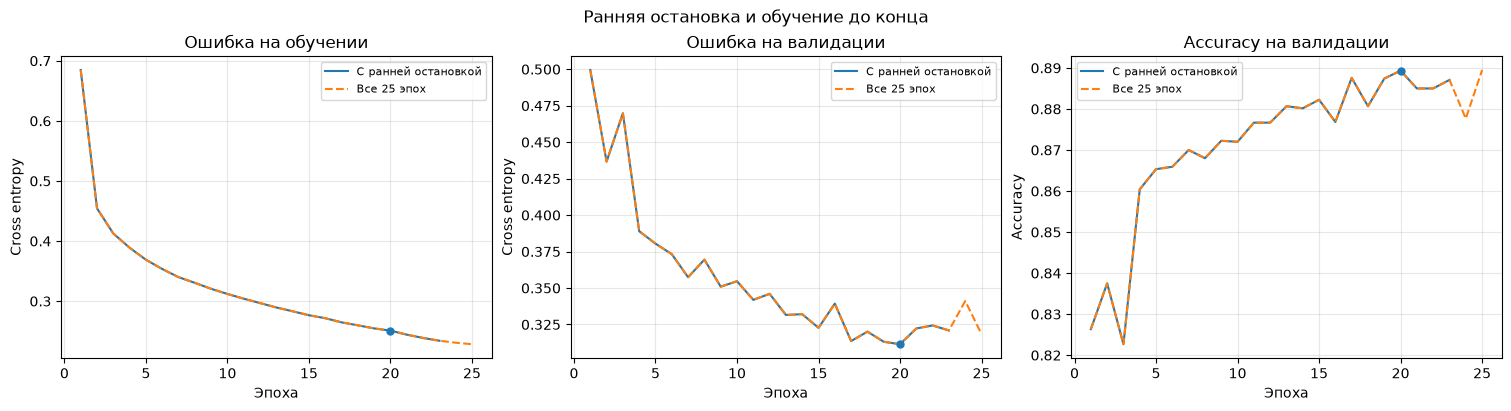

Эпохи, когда train loss снизился, а val loss вырос: [3, 8, 10, 12, 14, 16, 18, 21, 22]
Остановка: эпоха 23; восстановлены веса эпохи 20.
Сэкономлено эпох: 2.


In [12]:
no_es_result, no_es_model = run_experiment(
    train_ds, val_ds, 'Без ранней остановки', lr=best_lr,
    epochs=REG_EPOCHS, **configs[best_name],
)
early_comparison = {
    'С ранней остановкой': best_result,
    'Все 25 эпох': no_es_result,
}
show_table(early_comparison)
plot_runs(early_comparison, 'Ранняя остановка и обучение до конца')

# До момента остановки оба запуска должны проходить одинаково.
assert best_result['history'] == no_es_result['history'][:best_result['epochs_run']]
history = regularization['Без регуляризации']['history']
overfit_epochs = [
    current['epoch'] for previous, current in zip(history, history[1:])
    if current['train_loss'] < previous['train_loss']
    and current['val_loss'] > previous['val_loss']
]
print('Эпохи, когда train loss снизился, а val loss вырос:', overfit_epochs)
print(f"Остановка: эпоха {best_result['epochs_run']}; "
      f"восстановлены веса эпохи {best_result['best_epoch']}.")
print(f"Сэкономлено эпох: {REG_EPOCHS - best_result['epochs_run']}.")

Рост val loss при снижении train loss — признак возможного переобучения. Одного скачка недостаточно для уверенного вывода, поэтому использую несколько эпох ожидания.

Ранняя остановка выбирает веса по val loss. Accuracy и macro-F1 при этом могут измениться в другую сторону: эти показатели оценивают разные свойства предсказаний.

 веса эпохи 20.
Сэкономлено эпох: 2.## 9. Итоговые метрики и ошибки

Строка матрицы соответствует настоящему классу, столбец — предсказанному. Числа вне главной диагонали показывают ошибки.

Accuracy: 88.93%
Macro-F1: 0.88953
Val loss: 0.31147


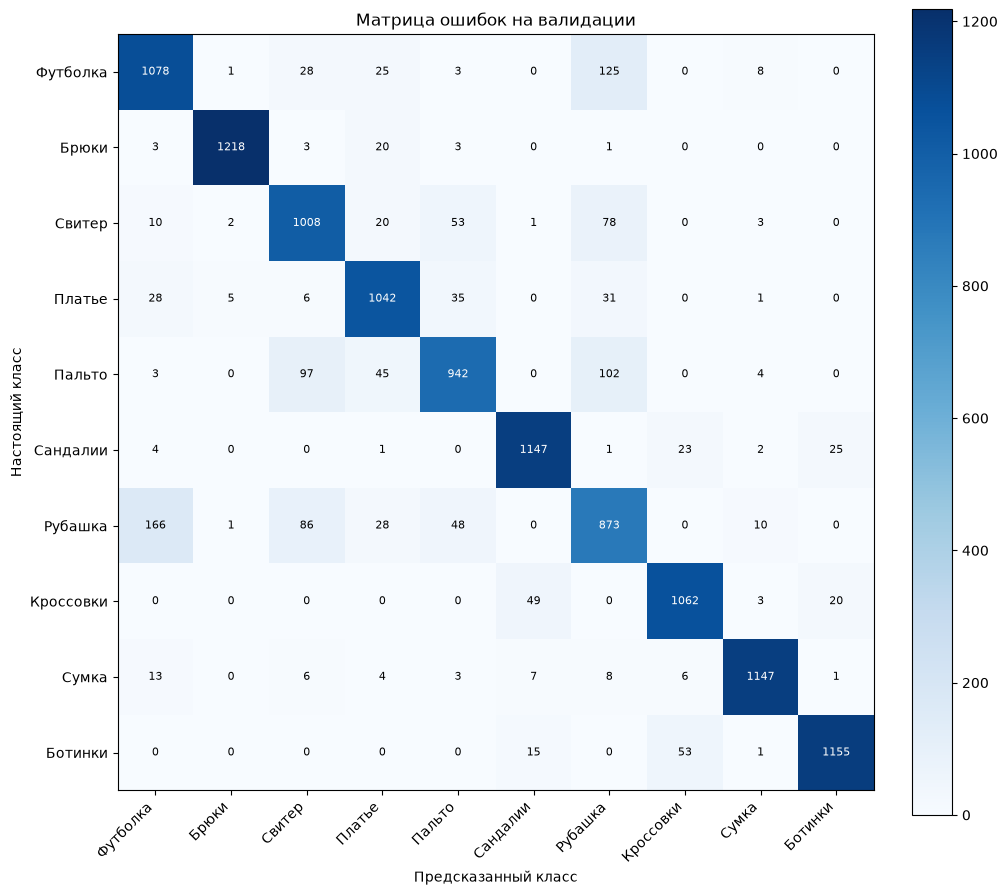

Самые частые ошибки:
Рубашка → Футболка: 166
Футболка → Рубашка: 125
Пальто → Рубашка: 102
Пальто → Свитер: 97
Рубашка → Свитер: 86


In [13]:
val_loader = DataLoader(val_ds, batch_size=256, shuffle=False,
                        generator=torch.Generator().manual_seed(SEED + 1))
final_metrics = evaluate(best_model, val_loader, nn.CrossEntropyLoss())
print(f"Accuracy: {final_metrics['accuracy']:.2%}")
print(f"Macro-F1: {final_metrics['macro_f1']:.5f}")
print(f"Val loss: {final_metrics['loss']:.5f}")

cm = np.array(final_metrics['confusion_matrix'])
fig, ax = plt.subplots(figsize=(10, 9), layout='constrained')
image = ax.imshow(cm, cmap='Blues')
ax.set(xticks=range(10), yticks=range(10),
       xticklabels=CLASSES, yticklabels=CLASSES,
       xlabel='Предсказанный класс', ylabel='Настоящий класс',
       title='Матрица ошибок на валидации')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
for i in range(10):
    for j in range(10):
        ax.text(j, i, str(cm[i, j]), ha='center', va='center', fontsize=8,
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
fig.colorbar(image, ax=ax)
display(fig)
plt.close(fig)

errors = cm.copy()
np.fill_diagonal(errors, 0)
print('Самые частые ошибки:')
for index in np.argsort(errors.ravel())[-5:][::-1]:
    true, predicted = np.unravel_index(index, errors.shape)
    print(f'{CLASSES[true]} → {CLASSES[predicted]}: {errors[true, predicted]}')

## 10. Дополнительный эксперимент: momentum

Сравниваю обычный SGD и SGD с momentum=0.9 при исходном lr=0.05. Momentum учитывает накопленное направление предыдущих градиентов. Бюджет тот же — восемь эпох.

SGD с momentum         01/8 train=0.6605 val=0.5046 acc=0.8177
SGD с momentum         04/8 train=0.3823 val=0.3991 acc=0.8561
SGD с momentum         08/8 train=0.3263 val=0.3513 acc=0.8741


| Запуск | min val loss | Итоговый val loss | Accuracy | Macro-F1 | Эпох / лучшая |
|---|---:|---:|---:|---:|---:|
| SGD | 0.47212 | 0.47212 | 83.86% | 0.83541 | 8 / 8 |
| SGD с momentum | 0.35129 | 0.35129 | 87.41% | 0.87264 | 8 / 8 |

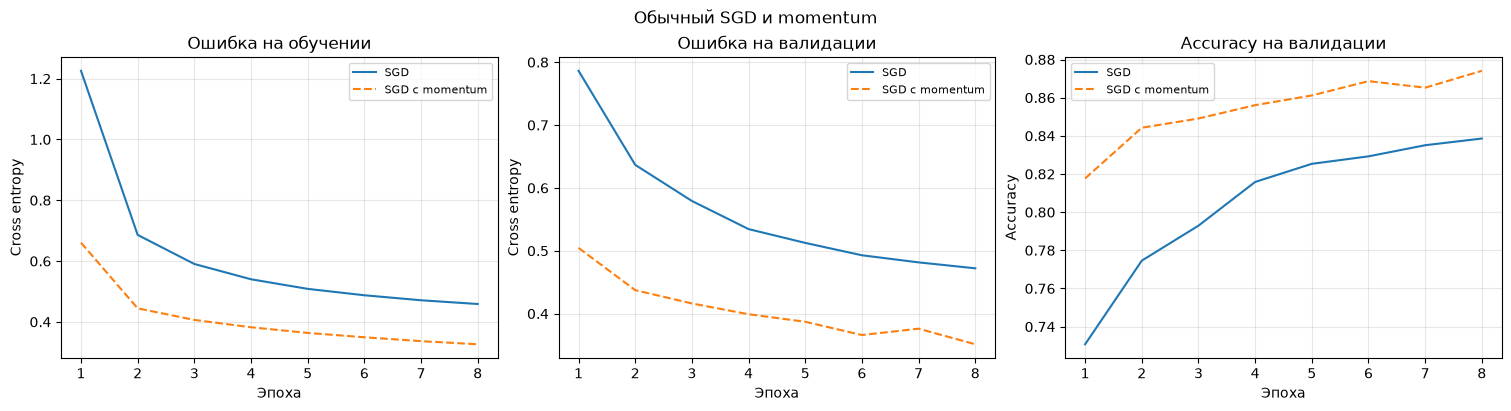

In [14]:
momentum_result, _ = run_experiment(
    train_ds, val_ds, 'SGD с momentum', lr=START_LR,
    epochs=COMPARE_EPOCHS, method='momentum',
)
show_table({'SGD': sgd_result, 'SGD с momentum': momentum_result})
plot_runs({'SGD': sgd_result, 'SGD с momentum': momentum_result},
          'Обычный SGD и momentum')

## 11. Небольшая проверка ручного шага

Проверяю ручное обновление на нескольких батчах с weight decay и без него. Начальные веса обеих моделей одинаковы. Проверка помогает заметить ошибку в формуле обновления, не запуская весь эксперимент заново.

In [15]:
for decay in [0.0, 1e-4]:
    set_seed()
    manual_check = MLP()
    optim_check = copy.deepcopy(manual_check)
    small_data = TensorDataset(torch.rand(11, 1, 28, 28), torch.arange(11) % 10)
    loader = DataLoader(small_data, batch_size=4)
    criterion = nn.CrossEntropyLoss()
    train_epoch_manual(manual_check, loader, criterion, lr=0.05, weight_decay=decay)
    optimizer = torch.optim.SGD(optim_check.parameters(), lr=0.05, weight_decay=decay)
    train_epoch_optim(optim_check, loader, criterion, optimizer)
    for a, b in zip(manual_check.parameters(), optim_check.parameters()):
        torch.testing.assert_close(a, b, atol=1e-7, rtol=1e-5)

assert sum(map(sum, final_metrics['confusion_matrix'])) == len(val_ds)
best_row = best_result['history'][best_result['best_epoch'] - 1]
assert abs(final_metrics['loss'] - best_row['val_loss']) < 1e-7
print('Ручной шаг совпадает с SGD. Матрица ошибок содержит всю валидацию.')
print('Итоговая модель соответствует лучшей эпохе.')

Ручной шаг совпадает с SGD. Матрица ошибок содержит всю валидацию.
Итоговая модель соответствует лучшей эпохе.


## Выводы

Ручной SGD и стандартный SGD дали практически одинаковые результаты. Максимальное различие весов составило **6.855 × 10⁻⁷**, что согласуется с округлением float32.

Из проверенных значений выбран **lr = 0.5**. Лучший результат показала сеть **без регуляризации**: accuracy на валидации — **88,93%**, macro-F1 — **0,88953**.

Dropout увеличил ошибку валидации относительно базовой сети на **0,00944**, а weight decay — на **0,01008**. В этом запуске оба способа регуляризации не улучшили качество модели.

Ранняя остановка завершила обучение на **23-й эпохе** и восстановила веса **20-й эпохи**. Ошибка выбранной модели составила **0,31147**, а после всех 25 эпох без ранней остановки — **0,31836**. Таким образом, восстановление лучших весов снизило ошибку валидации и позволило сэкономить две эпохи обучения. Чаще всего модель путала похожие виды одежды: рубашки, футболки, свитеры и пальто.

SGD с momentum получил ошибку валидации **0,35129**, обычный SGD при том же lr — **0,47212**. В этом сравнении momentum улучшил результат. Оба запуска выполнены при **lr = 0.05**; отдельный подбор lr для momentum не проводился.

Гиперпараметры выбирались по этой же валидационной выборке. Поэтому полученные метрики подходят для сравнения моделей в работе, но не заменяют оценку на независимом тестовом наборе. Все выводы относятся к seed=42 и выбранному числу эпох.